In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
!pip install -q torch torchvision matplotlib pillow tqdm

In [ ]:
import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset.zip to dataset.zip


In [ ]:
import zipfile

with zipfile.ZipFile("dataset.zip", "r") as zip_ref:
    zip_ref.extractall("/content/dataset")

print("Dataset extracted successfully")

Dataset extracted successfully


In [ ]:
class ColorizationDataset(Dataset):

    def __init__(self, root):

        self.root = root

        self.images = []

        for folder, _, files in os.walk(root):

            for file in files:

                if file.lower().endswith(
                    (".jpg", ".jpeg", ".png")
                ):

                    self.images.append(
                        os.path.join(folder, file)
                    )

        self.transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                (0.5, 0.5, 0.5),
                (0.5, 0.5, 0.5)
            )
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image = Image.open(
            self.images[index]
        ).convert("RGB")

        image = self.transform(image)

        # Random horizontal flip
        if random.random() > 0.5:
            image = transforms.functional.hflip(image)

        # Convert RGB to grayscale
        gray = transforms.functional.rgb_to_grayscale(
            image,
            num_output_channels=1
        )

        return gray, image


dataset = ColorizationDataset("/content/dataset")

loader = DataLoader(
    dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Total images:", len(dataset))

Total images: 128


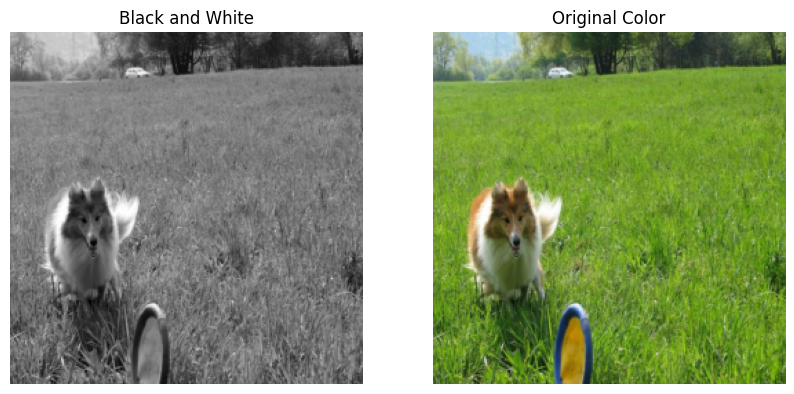

In [ ]:
gray, color = next(iter(loader))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray[0].squeeze(), cmap="gray")
plt.title("Black and White")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    ((color[0].permute(1, 2, 0) + 1) / 2).clamp(0, 1)
)
plt.title("Original Color")
plt.axis("off")

plt.show()

In [ ]:
class DownBlock(nn.Module):

    def __init__(self, in_channels, out_channels, normalize=True):

        super().__init__()

        layers = [
            nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=False)
        ]

        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))

        layers.append(nn.LeakyReLU(0.2, inplace=True))

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class UpBlock(nn.Module):

    def __init__(self, in_channels, out_channels, dropout=False):

        super().__init__()

        layers = [
            nn.ConvTranspose2d(
                in_channels, out_channels, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        ]

        if dropout:
            layers.append(nn.Dropout(0.5))

        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat([x, skip], dim=1)


class Generator(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.d1 = DownBlock(1, 64, False)
        self.d2 = DownBlock(64, 128)
        self.d3 = DownBlock(128, 256)
        self.d4 = DownBlock(256, 512)
        self.d5 = DownBlock(512, 512)
        self.d6 = DownBlock(512, 512)
        self.d7 = DownBlock(512, 512)
        self.d8 = DownBlock(512, 512)

        # Decoder
        self.u1 = UpBlock(512, 512, True)
        self.u2 = UpBlock(1024, 512, True)
        self.u3 = UpBlock(1024, 512, True)
        self.u4 = UpBlock(1024, 512)
        self.u5 = UpBlock(1024, 256)
        self.u6 = UpBlock(512, 128)
        self.u7 = UpBlock(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, x):

        # Encoder
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        d8 = self.d8(d7)

        # Decoder
        u1 = self.u1(d8, d7)
        u2 = self.u2(u1, d6)
        u3 = self.u3(u2, d5)
        u4 = self.u4(u3, d4)
        u5 = self.u5(u4, d3)
        u6 = self.u6(u5, d2)
        u7 = self.u7(u6, d1)

        return self.final(u7)

In [ ]:
class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            nn.Conv2d(4, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 1, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 1)
        )

    def forward(self, gray, color):

        combined = torch.cat([gray, color], dim=1)

        return self.model(combined)

In [ ]:
G = Generator().to(device)
D = Discriminator().to(device)

# Loss functions
criterion_GAN = nn.BCEWithLogitsLoss()
criterion_L1 = nn.L1Loss()

# Optimizers
optimizer_G = optim.Adam(
    G.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

lambda_L1 = 100

print("Generator and Discriminator initialized")

Generator and Discriminator initialized


In [ ]:
epochs = 50

for epoch in range(epochs):

    G.train()
    D.train()

    total_G_loss = 0
    total_D_loss = 0

    progress = tqdm(loader)

    for gray, real_color in progress:

        gray = gray.to(device)
        real_color = real_color.to(device)

        # ==========================
        # 1. Train Discriminator
        # ==========================

        fake_color = G(gray)

        real_output = D(gray, real_color)
        fake_output = D(gray, fake_color.detach())

        real_labels = torch.ones_like(real_output)
        fake_labels = torch.zeros_like(fake_output)

        loss_real = criterion_GAN(
            real_output, real_labels
        )

        loss_fake = criterion_GAN(
            fake_output, fake_labels
        )

        loss_D = (loss_real + loss_fake) / 2

        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        # ==========================
        # 2. Train Generator
        # ==========================

        fake_color = G(gray)

        fake_output = D(gray, fake_color)

        loss_GAN = criterion_GAN(
            fake_output,
            torch.ones_like(fake_output)
        )

        loss_L1 = criterion_L1(
            fake_color, real_color
        )

        loss_G = loss_GAN + lambda_L1 * loss_L1

        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        total_G_loss += loss_G.item()
        total_D_loss += loss_D.item()

        progress.set_description(
            f"Epoch {epoch+1}/{epochs}"
        )

    avg_G = total_G_loss / len(loader)
    avg_D = total_D_loss / len(loader)

    print(
        f"Epoch {epoch+1}: "
        f"G Loss = {avg_G:.4f}, "
        f"D Loss = {avg_D:.4f}"
    )

print("Training completed!")

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 1: G Loss = 35.4264, D Loss = 0.6909


  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 2: G Loss = 21.7658, D Loss = 0.5779


  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 3: G Loss = 20.1705, D Loss = 0.5188


... (99 outputs left out)

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 49: G Loss = 11.9699, D Loss = 0.5770


  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 50: G Loss = 12.1538, D Loss = 0.5690
Training completed!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

save_path = "/content/drive/MyDrive/GAN_Project"

os.makedirs(save_path, exist_ok=True)

torch.save(
    G.state_dict(),
    save_path + "/generator.pth"
)

torch.save(
    D.state_dict(),
    save_path + "/discriminator.pth"
)

print("Models saved successfully!")

Mounted at /content/drive
Models saved successfully!


In [ ]:
from google.colab import files

uploaded_test = files.upload()

test_image_path = next(iter(uploaded_test.keys()))

print("Uploaded:", test_image_path)

Saving 57ad560cc7f5e5ff1beefec8b81e016b.jpg to 57ad560cc7f5e5ff1beefec8b81e016b.jpg
Uploaded: 57ad560cc7f5e5ff1beefec8b81e016b.jpg


In [ ]:
def colorize_image(image_path):

    G.eval()

    original = Image.open(image_path).convert("L")

    # Resize input
    image = original.resize((256, 256))

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    gray = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():

        generated = G(gray)

    # Convert output to RGB
    generated = generated.squeeze(0).cpu()

    generated = (generated + 1) / 2
    generated = generated.clamp(0, 1)

    generated = transforms.ToPILImage()(generated)

    return original, generated


original, colorized = colorize_image(test_image_path)

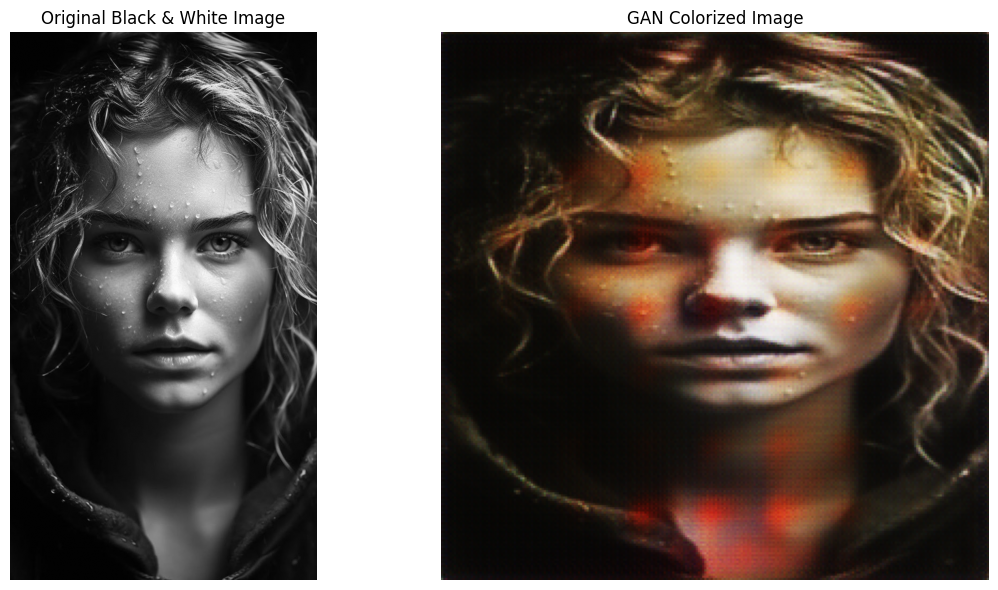

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original Black & White Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(colorized)
plt.title("GAN Colorized Image")
plt.axis("off")

plt.tight_layout()
plt.show()